In [156]:
from astropy.io import fits
from astropy.table import Table
import matplotlib.pyplot as plt
from IPython.display import display
import os
import numpy as np
import sep
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.nddata import Cutout2D
from scipy.ndimage import find_objects, binary_opening, binary_closing
from astropy.convolution import Gaussian2DKernel, convolve, convolve_fft
from scipy.ndimage import gaussian_filter

In [34]:
def jadesShow(fits_file):
    with fits.open(fits_file) as hdul:
        sci_data = hdul['SCI'].data
        
    vmin, vmax = np.percentile(sci_data, [1, 99])  # clip extremes

    plt.imshow(np.arcsinh(sci_data), origin='lower', cmap='viridis')
    plt.colorbar(label="Flux")
    plt.title("SCI Extension (Raw)")
    plt.show()

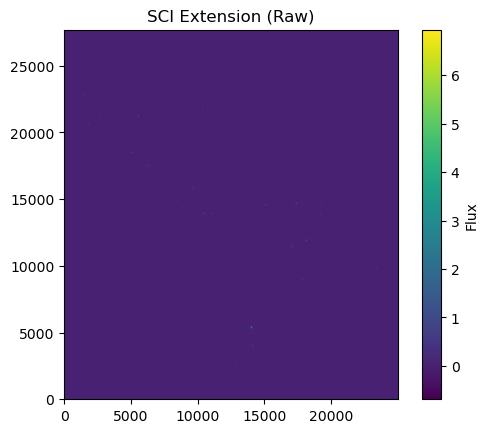

In [11]:
jadesShow(image)

In [84]:
# Files
sci_file = 'mastDownload/HLSP/hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0/hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0_drz.fits'
seg_file = 'mastDownload/HLSP/hlsp_jades_jwst_nircam_goods-s-deep_segmentation_v2.0_drz.fits'

# Load SCI image WCS
with fits.open(sci_file) as hdul:
    hdr = hdul["SCI"].header
    wcs = WCS(hdr)

# Load segmentation map
segmap = fits.getdata(seg_file)

# Fast galaxy ID extraction
max_id = segmap.max()
galaxy_ids = np.arange(1, max_id + 1)

# Find slices for all labeled objects
slices = find_objects(segmap)

# Build catalog list
catalog = []

for gal_id in galaxy_ids:
    sl = slices[gal_id - 1]  # ID 1 → index 0
    if sl is None:
        continue  # ID not present
    
    y_slice, x_slice = sl
    seg_cut = segmap[y_slice, x_slice]
    
    # Pixels belonging to this galaxy
    y_inds, x_inds = np.where(seg_cut == gal_id)
    
    # Centroid in pixel coordinates
    x_cent = x_inds.mean()
    y_cent = y_inds.mean()
    
    # Convert to RA/Dec
    ra, dec = wcs.all_pix2world(x_cent + x_slice.start, y_cent + y_slice.start, 0)
    
    # Bounding box
    x_min = x_inds.min() + x_slice.start
    x_max = x_inds.max() + x_slice.start
    y_min = y_inds.min() + y_slice.start
    y_max = y_inds.max() + y_slice.start
    
    n_pixels = len(x_inds)
    
    catalog.append({
        "ID": gal_id,
        "X_CENT": x_cent + x_slice.start,
        "Y_CENT": y_cent + y_slice.start,
        "RA": ra,
        "DEC": dec,
        "X_MIN": x_min,
        "X_MAX": x_max,
        "Y_MIN": y_min,
        "Y_MAX": y_max,
        "NPixels": n_pixels
    })

# Convert to DataFrame for pretty printing
gal_df = pd.DataFrame(catalog)

# Print catalog
print(gal_df)

# Optionally save to CSV
# gal_df.to_csv("galaxy_catalog_from_segmap.csv", index=False)

Set DATE-AVG to '2022-10-08T02:26:24.819' from MJD-AVG.
Set DATE-END to '2022-10-09T02:34:11.369' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    22.090597 from OBSGEO-[XYZ].
Set OBSGEO-H to 1234812278.786 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


           ID        X_CENT        Y_CENT                  RA  \
0         519  12917.887640   2553.393258     53.113404282635   
1         522  12893.081633   2556.714286   53.11363819936744   
2         528  12930.000000   2562.500000   53.11329007277288   
3         529  12891.016667   2566.475000  53.113657678307845   
4         538  12886.097087   2577.621359   53.11370407642142   
...       ...           ...           ...                 ...   
93995  298458  11173.078212  20518.662942   53.12984764981832   
93996  298459  10913.994318  19265.418561  53.132288294197075   
93997  298460  10853.000000  19570.000000  53.132862482825026   
93998  298461  11238.122807  19279.807018   53.12923575350272   
93999  298462   1254.019608  22096.843137  53.223240791188246   

                       DEC  X_MIN  X_MAX  Y_MIN  Y_MAX  NPixels  
0       -27.92378173384804  12910  12926   2546   2561      178  
1        -27.9237540792317  12884  12901   2549   2565      196  
2      -27.9237058501

In [153]:
def export_galaxy_cutouts(
    sci_file,
    seg_file=None,   # optional: JADES needs it, CEERS uses BKGMASK
    outdir="galaxy_cutouts",
    galaxy_ids=None,
    galaxy_id_range=None,
    xy_range=None,
    ra_dec_range=None,
    padding=50,
    sep_thresh=1.5,
    max_flux_threshold=None,
    gaussian_sigma=1.0,
    min_area=20,
    max_distance=None,
    ceers_bin=2   # bin factor for CEERS SEP to speed up
):
    """
    Export per-galaxy cutouts from JWST SCI+ERR images with SEP masks.

    CEERS:
    - Uses BKGMASK as segmentation map
    - Performs a single SEP run over binned region containing all selected galaxies
    - Skips Gaussian smoothing for speed

    JADES:
    - Requires external seg_file
    - Processes each galaxy individually
    """
    import os
    import numpy as np
    from astropy.io import fits
    from astropy.wcs import WCS
    from astropy.nddata import Cutout2D
    import sep
    from scipy.ndimage import gaussian_filter, zoom
    from scipy.ndimage import find_objects
    from tqdm import tqdm

    os.makedirs(outdir, exist_ok=True)

    # --- Load science and error images ---
    with fits.open(sci_file) as hdul:
        sci_data = hdul["SCI"].data.astype(np.float32)
        err_data = hdul["ERR"].data.astype(np.float32)
        hdr = hdul["SCI"].header
        wcs = WCS(hdr)

        # Detect CEERS vs JADES
        if "BKGMASK" in hdul:
            segmap = hdul["BKGMASK"].data.astype(np.int32)
            mode = "CEERS"
        elif seg_file is not None:
            segmap = fits.getdata(seg_file).astype(np.int32)
            mode = "JADES"
        else:
            raise ValueError("No segmentation map found. Provide seg_file for JADES or BKGMASK extension for CEERS.")

    # --- Determine galaxy IDs ---
    max_id = segmap.max()
    all_ids = np.arange(1, max_id + 1)
    if galaxy_ids is not None:
        selected_ids = [gid for gid in galaxy_ids if gid in all_ids]
    elif galaxy_id_range is not None:
        min_id, max_id_range = galaxy_id_range
        selected_ids = [gid for gid in all_ids if min_id <= gid <= max_id_range]
    else:
        selected_ids = all_ids

    # --- Progress bar setup ---
    pbar = tqdm(total=len(selected_ids), desc=f'Processing galaxies ({mode})')

    # --- Compute slices ---
    slices = find_objects(segmap)
    valid_slices = [slices[gid-1] for gid in selected_ids if slices[gid-1] is not None]

    if mode == "CEERS":
        # Minimal region containing all selected galaxies
        y_start = max(min(sl[0].start for sl in valid_slices) - padding, 0)
        y_end   = min(max(sl[0].stop  for sl in valid_slices) + padding, sci_data.shape[0])
        x_start = max(min(sl[1].start for sl in valid_slices) - padding, 0)
        x_end   = min(max(sl[1].stop  for sl in valid_slices) + padding, sci_data.shape[1])

        # Extract cutout and bin
        sci_cut_all = sci_data[y_start:y_end, x_start:x_end].copy()
        err_cut_all = err_data[y_start:y_end, x_start:x_end].copy()
        sci_cut_binned = np.ascontiguousarray(sci_cut_all[::ceers_bin, ::ceers_bin])
        err_cut_binned = np.ascontiguousarray(err_cut_all[::ceers_bin, ::ceers_bin])

        # SEP background & segmentation on binned cutout
        bkg = sep.Background(sci_cut_binned)
        data_sub_binned = sci_cut_binned - bkg
        objects, segmap_sep_binned = sep.extract(
            data_sub_binned,
            thresh=sep_thresh,
            err=err_cut_binned,
            segmentation_map=True
        )
        segmap_sep_full = zoom(segmap_sep_binned, ceers_bin, order=0).astype(np.int32)

    # --- Process each galaxy ---
    for gal_id in selected_ids:
        sl = slices[gal_id - 1]
        if sl is None:
            pbar.update(1)
            continue

        y_slice, x_slice = sl
        seg_cut = segmap[y_slice, x_slice]
        mask = (seg_cut == gal_id)
        if not mask.any():
            pbar.update(1)
            continue

        # Max-flux pre-filter
        galaxy_max_flux = sci_data[y_slice, x_slice][mask].max()
        if max_flux_threshold is not None and galaxy_max_flux < max_flux_threshold:
            pbar.update(1)
            continue

        # Centroid
        y_inds, x_inds = np.where(mask)
        x_cent = x_inds.mean() + x_slice.start
        y_cent = y_inds.mean() + y_slice.start

        # XY range filter
        if xy_range is not None:
            (x_min_filter, x_max_filter), (y_min_filter, y_max_filter) = xy_range
            if not (x_min_filter <= x_cent <= x_max_filter and y_min_filter <= y_cent <= y_max_filter):
                pbar.update(1)
                continue

        # RA/Dec filter
        if ra_dec_range is not None:
            ra, dec = wcs.all_pix2world(x_cent, y_cent, 0)
            (ra_min, ra_max), (dec_min, dec_max) = ra_dec_range
            if not (ra_min <= ra <= ra_max and dec_min <= dec <= dec_max):
                pbar.update(1)
                continue

        # Bounding box with padding
        x_min = max(x_inds.min() + x_slice.start - padding, 0)
        x_max = min(x_inds.max() + x_slice.start + padding, sci_data.shape[1] - 1)
        y_min = max(y_inds.min() + y_slice.start - padding, 0)
        y_max = min(y_inds.max() + y_slice.start + padding, sci_data.shape[0] - 1)

        # Cutouts
        cutout_pos = (x_cent, y_cent)
        cutout_size = (y_max - y_min + 1, x_max - x_min + 1)
        sci_cut = Cutout2D(sci_data, cutout_pos, cutout_size, wcs=wcs, copy=True)
        err_cut = Cutout2D(err_data, cutout_pos, cutout_size, wcs=wcs, copy=True)
        sci_cut_c = np.ascontiguousarray(sci_cut.data, dtype=np.float32)
        err_cut_c = np.ascontiguousarray(err_cut.data, dtype=np.float32)

        # JADES Gaussian smoothing
        if mode == "JADES" and gaussian_sigma > 0:
            sci_cut_c = gaussian_filter(sci_cut_c, sigma=gaussian_sigma)

        # SEP segmentation
        if mode == "CEERS":
            segmap_sep = segmap_sep_full[
                y_min - y_start:y_max - y_start,
                x_min - x_start:x_max - x_start
            ]
            objects = None
        else:
            bkg = sep.Background(sci_cut_c)
            data_sub = sci_cut_c - bkg
            objects, segmap_sep = sep.extract(
                data_sub,
                thresh=sep_thresh,
                err=err_cut_c,
                segmentation_map=True
            )

        # Build mask (keep all but central object)
        mask_sep = np.zeros_like(segmap_sep, dtype=np.uint8)
        if objects is not None and len(objects) > 0:
            x_center_local = sci_cut.shape[1] / 2
            y_center_local = sci_cut.shape[0] / 2
            distances = (objects["x"] - x_center_local)**2 + (objects["y"] - y_center_local)**2
            central_idx = np.argmin(distances)
            central_label = central_idx + 1
            for i, obj in enumerate(objects):
                label = i + 1
                if label == central_label:
                    continue
                dx = obj["x"] - x_center_local
                dy = obj["y"] - y_center_local
                dist2 = dx**2 + dy**2
                area = obj["a"] * obj["b"] * np.pi
                if (max_distance is not None and np.sqrt(dist2) > max_distance) or (area < min_area):
                    continue
                mask_sep[segmap_sep == label] = 1
            mask_sep = (mask_sep > 0).astype(np.uint8)

        # Save cutouts
        sci_hdu = fits.PrimaryHDU(data=sci_cut.data, header=sci_cut.wcs.to_header())
        sci_hdu.writeto(os.path.join(outdir, f"cutout_sci_{gal_id}.fits"), overwrite=True)
        err_hdu = fits.PrimaryHDU(data=err_cut.data, header=sci_cut.wcs.to_header())
        err_hdu.writeto(os.path.join(outdir, f"cutout_err_{gal_id}.fits"), overwrite=True)
        seg_hdu = fits.PrimaryHDU(data=segmap_sep.astype(np.int16), header=sci_cut.wcs.to_header())
        seg_hdu.writeto(os.path.join(outdir, f"segmap_{gal_id}.fits"), overwrite=True)
        mask_hdu = fits.PrimaryHDU(data=mask_sep, header=sci_cut.wcs.to_header())
        mask_hdu.writeto(os.path.join(outdir, f"mask_{gal_id}.fits"), overwrite=True)

        pbar.update(1)  # ✅ tqdm update instead of print

    pbar.close()


In [154]:
jseg_file = 'mastDownload/HLSP/hlsp_jades_jwst_nircam_goods-s-deep_segmentation_v2.0_drz.fits'
jsci_file = 'mastDownload/HLSP/hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0/hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0_drz.fits'
csci_file = 'mastDownload/HLSP/hlsp_ceers_jwst_nircam_nircam5_f115w_dr0.6_i2d/hlsp_ceers_jwst_nircam_nircam5_f115w_dr0.6_i2d.fits'

In [155]:
export_galaxy_cutouts(jsci_file, jseg_file, outdir="galaxy_cutouts", max_flux_threshold=0.1, galaxy_id_range=(202206,211158))

Set DATE-AVG to '2022-10-08T02:26:24.819' from MJD-AVG.
Set DATE-END to '2022-10-09T02:34:11.369' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    22.090597 from OBSGEO-[XYZ].
Set OBSGEO-H to 1234812278.786 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


NameError: name 'gaussian_filter' is not defined

In [152]:
export_galaxy_cutouts(csci_file, None, outdir="ceers_galaxy_cutouts", max_flux_threshold=0.1, galaxy_id_range=(0,1090))

Set DATE-AVG to '2022-12-23T09:54:11.188' from MJD-AVG.
Set DATE-END to '2022-12-24T19:19:42.661' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to     8.534125 from OBSGEO-[XYZ].
Set OBSGEO-H to 1680304337.829 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


KeyboardInterrupt: 